# Assignment 1 – Credit Card Fraud Detection (Machine Learning)

**Goal:** build a classifier that flags fraudulent card transactions while keeping false alarms on genuine customers low.

**Data:** `fraudTrain.csv` (Jan 2019 – Jun 2020) and `fraudTest.csv` (Jun – Dec 2020). The test file is *later in time* than the training file, which mimics real deployment (we train on the past and predict the future).

**Approach**
1. Explore the data and quantify the class imbalance
2. Engineer features (time, distance customer ↔ merchant, age, spending behaviour per card)
3. Handle imbalance (class weights + majority-class undersampling) and compare models
4. Choose the decision threshold on a validation set using a business cost trade-off
5. Evaluate once on the untouched test set

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score, f1_score,
                             classification_report, roc_curve)
sns.set_theme(style="whitegrid"); RNG = 42
DATA = "/home/claude/data/"

## 1. Load data and look at the class imbalance

In [2]:
USE = ["trans_date_trans_time", "cc_num", "category", "amt", "gender", "lat", "long", "city_pop",
       "dob", "merch_lat", "merch_long", "is_fraud"]   # names, streets and transaction ids are not used
train = pd.read_csv(DATA + "fraudTrain.csv", usecols=USE)
test = pd.read_csv(DATA + "fraudTest.csv", usecols=USE)
print("train:", train.shape, "| test:", test.shape)
print("missing values:", int(train.isna().sum().sum()), "/", int(test.isna().sum().sum()))
for n, d in [("train", train), ("test", test)]:
    print(f"{n}: fraud = {d.is_fraud.sum():,} of {len(d):,}  ({d.is_fraud.mean()*100:.3f}%)  -> 1 fraud per {int(1/d.is_fraud.mean())} transactions")

train: (1296675, 12) | test: (555719, 12)
missing values: 0 / 0
train: fraud = 7,506 of 1,296,675  (0.579%)  -> 1 fraud per 172 transactions
test: fraud = 2,145 of 555,719  (0.386%)  -> 1 fraud per 259 transactions


Fraud is only ~0.58 % of training data. A model that always predicts "legitimate" would be **99.4 % accurate and catch zero fraud**, so accuracy is useless here. I use **precision, recall, F1 and PR-AUC** instead.

## 2. Exploratory analysis – what does fraud look like?

              count    mean     std   min     25%     50%     75%       max
is_fraud                                                                   
0         1289169.0   67.67  154.01  1.00    9.61   47.28   82.54  28948.90
1            7506.0  531.32  390.56  1.06  245.66  396.50  900.88   1376.04

Top fraud-rate categories (%):
 category
shopping_pos    0.72
grocery_pos     1.41
misc_net        1.45
shopping_net    1.76
Name: is_fraud, dtype: float64

Peak fraud hours (%):
 hour
0     1.49
1     1.53
23    2.84
22    2.88
Name: is_fraud, dtype: float64


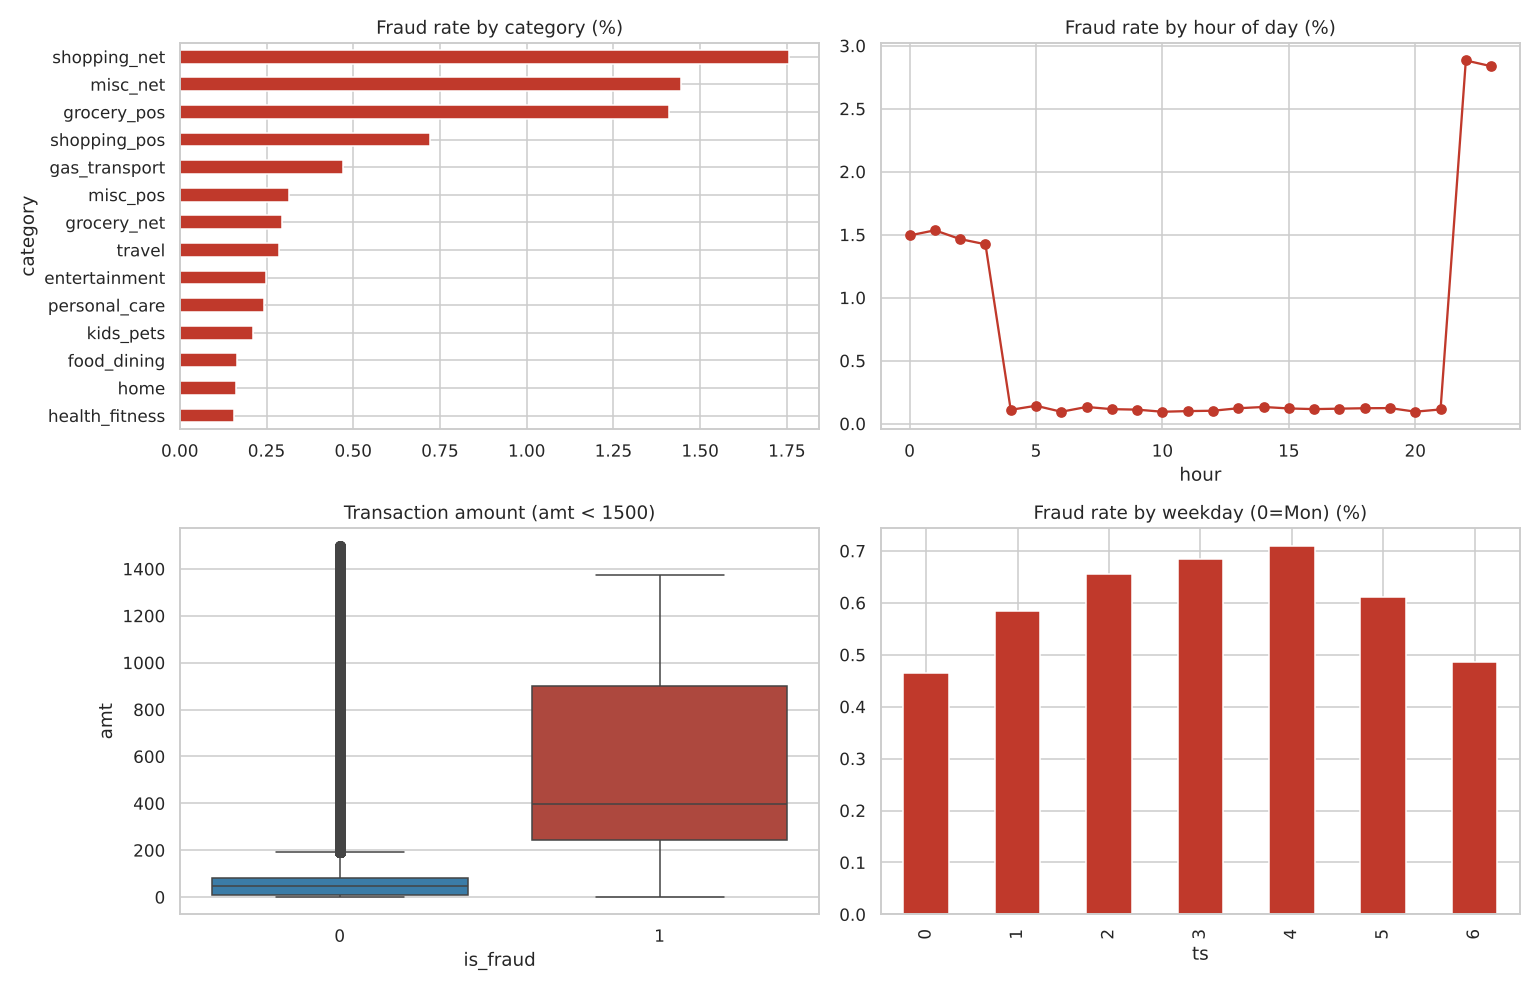

In [3]:
for d in (train, test):
    d["ts"] = pd.to_datetime(d["trans_date_trans_time"])
    d["hour"] = d.ts.dt.hour.astype("int8")
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
cat = train.groupby("category").is_fraud.mean().sort_values() * 100
cat.plot.barh(ax=ax[0, 0], color="#c0392b"); ax[0, 0].set_title("Fraud rate by category (%)")
h = train.groupby("hour").is_fraud.mean() * 100
h.plot(ax=ax[0, 1], marker="o", color="#c0392b"); ax[0, 1].set_title("Fraud rate by hour of day (%)")
sns.boxplot(data=train[train.amt < 1500], x="is_fraud", y="amt", ax=ax[1, 0], palette=["#2980b9", "#c0392b"])
ax[1, 0].set_title("Transaction amount (amt < 1500)")
train.groupby(train.ts.dt.dayofweek).is_fraud.mean().mul(100).plot.bar(ax=ax[1, 1], color="#c0392b")
ax[1, 1].set_title("Fraud rate by weekday (0=Mon) (%)")
plt.tight_layout(); plt.savefig("/home/claude/fig_eda.png", dpi=110); plt.close()
print(train.groupby("is_fraud").amt.describe().round(2))
print("\nTop fraud-rate categories (%):\n", cat.tail(4).round(2))
print("\nPeak fraud hours (%):\n", h.sort_values().tail(4).round(2))

**Findings:** fraud is concentrated in a few categories (online shopping, grocery POS, misc online), happens mostly **late at night (22:00–03:00)**, and involves **much larger amounts** than genuine spend. These patterns drive the features below.

## 3. Feature engineering
Raw identifiers (name, street, transaction number) carry no generalisable signal, so they are dropped. I build:
* **Time:** hour, weekday, night flag
* **Distance** between customer home and merchant (haversine, km)
* **Customer age**
* **Per-card behaviour:** time since the card's previous transaction, and amount relative to that card's running average (*using only past transactions, so there is no leakage*)
* **Categorical** fields encoded numerically (category, gender; state via frequency of fraud is avoided to prevent leakage)

In [4]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def build(df):
    d = df.copy()
    d["ts"] = pd.to_datetime(d["trans_date_trans_time"])
    d = d.sort_values(["cc_num", "ts"]).reset_index(drop=True)
    d["hour"] = d.ts.dt.hour
    d["weekday"] = d.ts.dt.dayofweek
    d["month"] = d.ts.dt.month
    d["is_night"] = ((d.hour >= 22) | (d.hour <= 3)).astype(int)
    d["distance_km"] = haversine(d.lat, d.long, d.merch_lat, d.merch_long)
    d["age"] = (d.ts - pd.to_datetime(d.dob)).dt.days / 365.25
    d["log_amt"] = np.log1p(d.amt)
    g = d.groupby("cc_num")
    d["secs_since_prev"] = g.ts.diff().dt.total_seconds().fillna(-1)
    # expanding mean of PAST amounts only (shift(1) prevents leakage)
    d["card_txn_count"] = g.cumcount()
    d["card_avg_amt"] = (g.amt.cumsum() - d.amt) / d.card_txn_count.replace(0, np.nan)
    d["amt_vs_card_avg"] = (d.amt / d.card_avg_amt).fillna(1.0)
    d["gender"] = (d.gender == "M").astype(int)
    d["category"] = d.category.astype("category")
    d = d.drop(columns=["trans_date_trans_time", "dob", "lat", "long", "merch_lat", "merch_long", "cc_num", "card_avg_amt"])
    return d.sort_values("ts").reset_index(drop=True)

tr_full, te = build(train), build(test)
del train, test; import gc; gc.collect()
cats = sorted(tr_full.category.cat.categories)
for d in (tr_full, te):
    d["category"] = pd.Categorical(d["category"], categories=cats)
    for c in cats:
        d["cat_" + c] = (d.category == c).astype(int)
FEATURES = (["amt", "log_amt", "hour", "weekday", "month", "is_night", "distance_km", "age", "gender",
             "city_pop", "secs_since_prev", "amt_vs_card_avg", "card_txn_count"] + ["cat_" + c for c in cats])
print(len(FEATURES), "features:", FEATURES)

27 features: ['amt', 'log_amt', 'hour', 'weekday', 'month', 'is_night', 'distance_km', 'age', 'gender', 'city_pop', 'secs_since_prev', 'amt_vs_card_avg', 'card_txn_count', 'cat_entertainment', 'cat_food_dining', 'cat_gas_transport', 'cat_grocery_net', 'cat_grocery_pos', 'cat_health_fitness', 'cat_home', 'cat_kids_pets', 'cat_misc_net', 'cat_misc_pos', 'cat_personal_care', 'cat_shopping_net', 'cat_shopping_pos', 'cat_travel']


## 4. Train / validation / test split (time-based)
* **Test** = the provided `fraudTest.csv` (never touched until the very end)
* **Validation** = the *last 3 months* of the training file (used to pick the model and the threshold)
* **Train** = everything before that
A random split would leak future patterns into training, so I split by time.

In [5]:
cut = tr_full.ts.max() - pd.Timedelta(days=90)
tr, va = tr_full[tr_full.ts < cut], tr_full[tr_full.ts >= cut]
Xtr, ytr = tr[FEATURES], tr.is_fraud
Xva, yva = va[FEATURES], va.is_fraud
Xte, yte = te[FEATURES], te.is_fraud
print(f"train {len(tr):,} (fraud {ytr.mean()*100:.3f}%) | val {len(va):,} (fraud {yva.mean()*100:.3f}%) | test {len(te):,} (fraud {yte.mean()*100:.3f}%)")

train 1,076,870 (fraud 0.582%) | val 219,805 (fraud 0.561%) | test 555,719 (fraud 0.386%)


## 5. Handling class imbalance
I compare three strategies on the validation set:
1. **Class weights** – penalise mistakes on fraud much more heavily
2. **Random undersampling** – keep all fraud rows and a random sample of legitimate rows (10 : 1 ratio)
3. **No handling** (baseline)

Oversampling with SMOTE was not used: with 1 M+ rows it is slow and adds synthetic points, while the dataset already holds thousands of real fraud examples.

In [6]:
rng = np.random.RandomState(RNG)
fraud_idx = ytr[ytr == 1].index
legit_idx = rng.choice(ytr[ytr == 0].index, size=len(fraud_idx) * 10, replace=False)
us_idx = np.concatenate([fraud_idx, legit_idx]); rng.shuffle(us_idx)
Xus, yus = Xtr.loc[us_idx], ytr.loc[us_idx]
print(f"undersampled training set: {len(yus):,} rows, fraud {yus.mean()*100:.1f}%")

scaler = StandardScaler().fit(Xtr)
def best_f1(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f = 2*pr*rc/(pr+rc+1e-12)
    i = np.nanargmax(f[:-1]); return f[i], th[i]

results, probs = [], {}
def run(name, model, X, y, scale=False):
    Xv = Xva
    if scale:
        sc = StandardScaler().fit(X); X, Xv = sc.transform(X), sc.transform(Xva)
    model.fit(X, y); p = model.predict_proba(Xv)[:, 1]; probs[name] = (model, p)
    f, t = best_f1(yva, p)
    results.append(dict(model=name, PR_AUC=average_precision_score(yva, p), ROC_AUC=roc_auc_score(yva, p), best_F1=f, threshold=t))

run("LogReg (class weight)", LogisticRegression(class_weight="balanced", max_iter=500), Xtr, ytr, scale=True)
run("RandomForest (undersampled)", RandomForestClassifier(n_estimators=150, min_samples_leaf=3, n_jobs=-1, random_state=RNG), Xus, yus)
run("HistGB (no handling)", HistGradientBoostingClassifier(max_iter=250, learning_rate=0.1, random_state=RNG), Xtr, ytr)
run("HistGB (class weight)", HistGradientBoostingClassifier(max_iter=250, learning_rate=0.1, class_weight="balanced", random_state=RNG), Xtr, ytr)
run("HistGB (undersampled)", HistGradientBoostingClassifier(max_iter=250, learning_rate=0.1, random_state=RNG), Xus, yus)
res = pd.DataFrame(results).set_index("model").round(4).sort_values("PR_AUC", ascending=False)
print(res)

undersampled training set: 68,992 rows, fraud 9.1%
                             PR_AUC  ROC_AUC  best_F1  threshold
model                                                           
HistGB (undersampled)        0.9414   0.9990   0.8796     0.8399
HistGB (class weight)        0.9378   0.9988   0.8753     0.9373
RandomForest (undersampled)  0.9205   0.9981   0.8666     0.7543
HistGB (no handling)         0.7409   0.8989   0.7926     0.1772
LogReg (class weight)        0.2718   0.9728   0.4729     0.9046


## 6. Pick the final model and the decision threshold
The default 0.5 threshold is wrong for rare-event problems, so I tune it on the **validation set** (never on test). Two candidates:
* **Balanced threshold** – maximises F1, i.e. treats missed fraud and false alarms as equally important. This matches the brief ("minimise false positives *and* false negatives, keep genuine customers happy") and is used as the **default**.
* **Security-first threshold** – minimises a business cost where a missed fraud costs its full amount and a false alarm costs a flat $10 (an adjustable assumption). Because the average fraud is ~$530, this pushes the threshold low, catching almost everything but alerting many more genuine customers.
Both are evaluated on the test set so the trade-off is visible.

Selected model: HistGB (undersampled)
cost-optimal threshold = 0.14 | F1-optimal threshold = 0.84


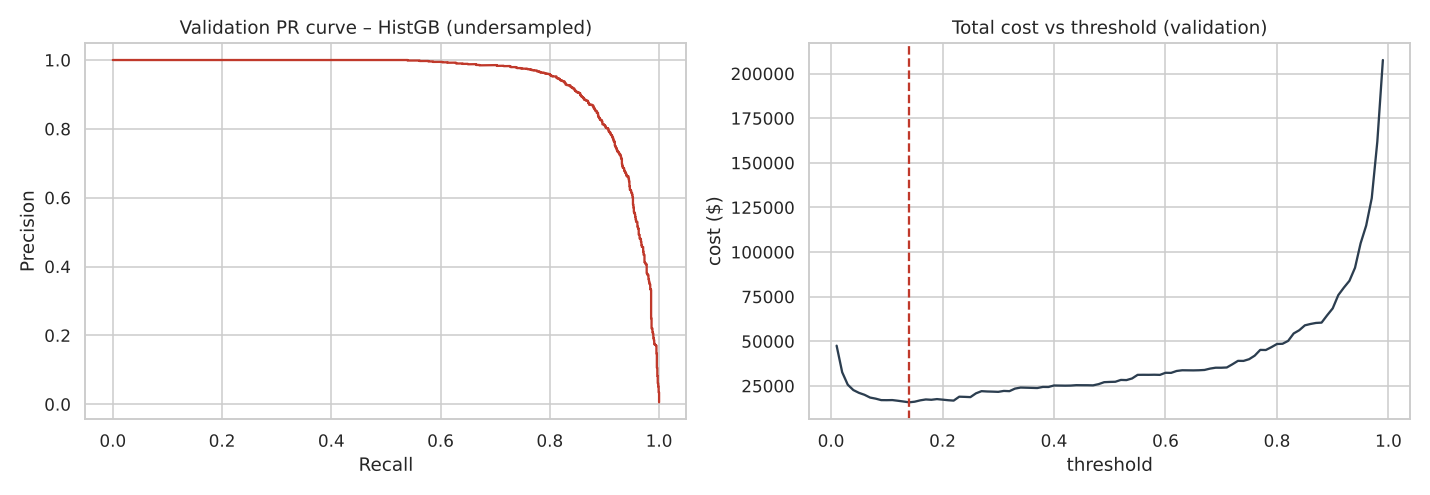

In [7]:
best_name = res.index[0]; model, pva = probs[best_name]
print("Selected model:", best_name)
FP_COST = 10.0
ths = np.linspace(0.01, 0.99, 99)
costs = []
for t in ths:
    pred = pva >= t
    fn = (~pred) & (yva == 1); fp = pred & (yva == 0)
    costs.append(va.amt[fn].sum() + FP_COST * fp.sum())
t_cost = ths[int(np.argmin(costs))]
f1v, t_f1 = best_f1(yva, pva)
print(f"cost-optimal threshold = {t_cost:.2f} | F1-optimal threshold = {t_f1:.2f}")
THRESH = t_f1          # balanced default; t_cost is the security-first alternative
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
pr, rc, _ = precision_recall_curve(yva, pva)
ax[0].plot(rc, pr, color="#c0392b"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title(f"Validation PR curve – {best_name}")
ax[1].plot(ths, costs, color="#2c3e50"); ax[1].axvline(t_cost, ls="--", color="#c0392b"); ax[1].set_title("Total cost vs threshold (validation)")
ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost ($)")
plt.tight_layout(); plt.savefig("/home/claude/fig_threshold.png", dpi=110); plt.close()

## 7. Final evaluation on the held-out test set
The chosen model is **retrained on the full training file (train + validation)** and scored once on `fraudTest.csv`.

threshold used: 0.84
              precision    recall  f1-score   support

       legit     0.9996    0.9983    0.9990    553574
       fraud     0.6791    0.9077    0.7769      2145

    accuracy                         0.9980    555719
   macro avg     0.8394    0.9530    0.8880    555719
weighted avg     0.9984    0.9980    0.9981    555719

ROC-AUC = 0.9982 | PR-AUC = 0.9151
Confusion matrix -> TN 552,654 | FP 920 | FN 198 | TP 1,947
False-positive rate: 0.166% of genuine transactions flagged
Fraud caught: 90.8% of cases | $1,102,686 of $1,133,325 fraud value stopped
Of every 100 alerts, 68 are real fraud


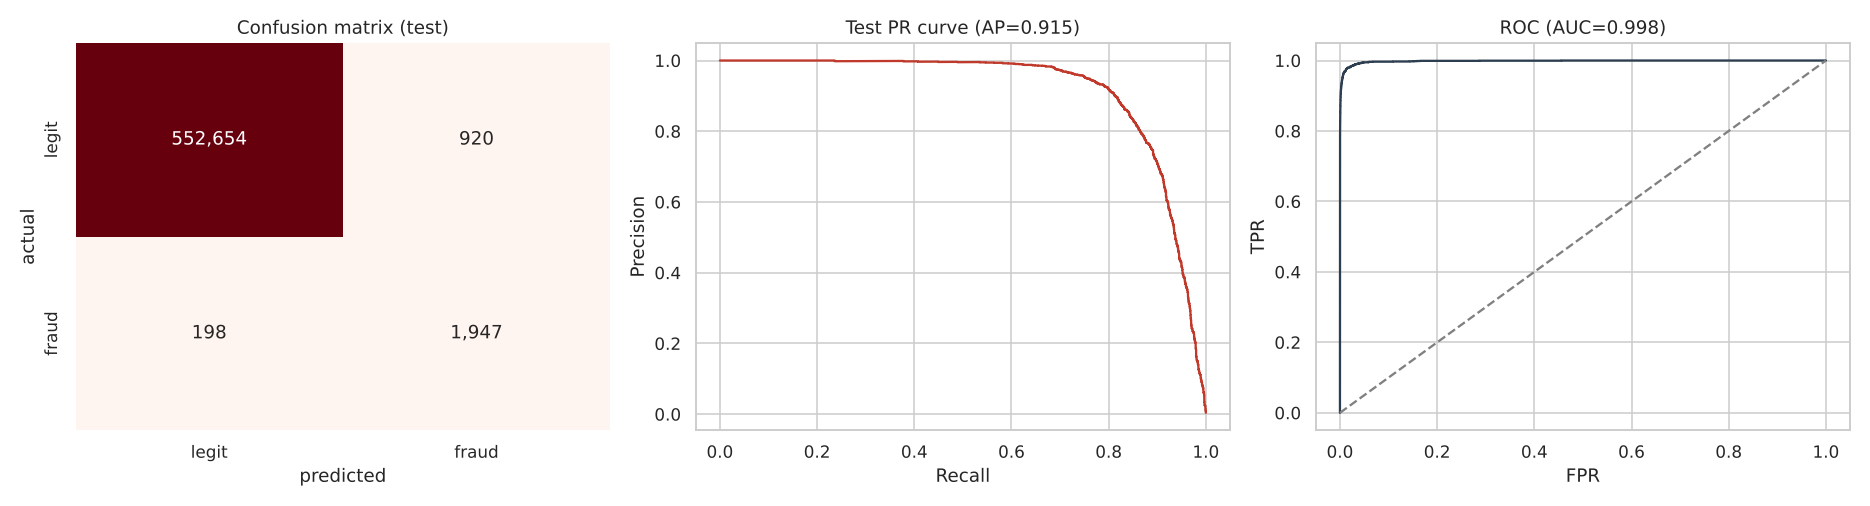

In [8]:
def make_final(name):
    if "undersampled" in name:
        r = np.random.RandomState(RNG); fi = tr_full.index[tr_full.is_fraud == 1]
        li = r.choice(tr_full.index[tr_full.is_fraud == 0], size=len(fi)*10, replace=False)
        idx = np.concatenate([fi, li]); r.shuffle(idx)
        return tr_full.loc[idx, FEATURES], tr_full.loc[idx, "is_fraud"]
    return tr_full[FEATURES], tr_full["is_fraud"]
Xf, yf = make_final(best_name)
final = HistGradientBoostingClassifier(max_iter=250, learning_rate=0.1, random_state=RNG).fit(Xf, yf)
pte = final.predict_proba(Xte)[:, 1]
pred = (pte >= THRESH).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
print(f"threshold used: {THRESH:.2f}")
print(classification_report(yte, pred, target_names=["legit", "fraud"], digits=4))
print(f"ROC-AUC = {roc_auc_score(yte, pte):.4f} | PR-AUC = {average_precision_score(yte, pte):.4f}")
print(f"Confusion matrix -> TN {tn:,} | FP {fp:,} | FN {fn:,} | TP {tp:,}")
print(f"False-positive rate: {fp/(fp+tn)*100:.3f}% of genuine transactions flagged")
print(f"Fraud caught: {tp/(tp+fn)*100:.1f}% of cases | ${te.amt[(pred==1)&(yte==1)].sum():,.0f} of ${te.amt[yte==1].sum():,.0f} fraud value stopped")
print(f"Of every 100 alerts, {tp/(tp+fp)*100:.0f} are real fraud")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt=",d", cmap="Reds", cbar=False, ax=ax[0],
            xticklabels=["legit", "fraud"], yticklabels=["legit", "fraud"]); ax[0].set_title("Confusion matrix (test)"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("actual")
pr, rc, _ = precision_recall_curve(yte, pte); ax[1].plot(rc, pr, color="#c0392b"); ax[1].set_title(f"Test PR curve (AP={average_precision_score(yte, pte):.3f})"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
fpr, tpr, _ = roc_curve(yte, pte); ax[2].plot(fpr, tpr, color="#2c3e50"); ax[2].plot([0, 1], [0, 1], "--", c="grey"); ax[2].set_title(f"ROC (AUC={roc_auc_score(yte, pte):.3f})"); ax[2].set_xlabel("FPR"); ax[2].set_ylabel("TPR")
plt.tight_layout(); plt.savefig("/home/claude/fig_test.png", dpi=110); plt.close()

## 8. Threshold trade-off on the test set (what the business can choose)
The rows at the chosen balanced threshold and the security-first threshold are included in the table.

In [9]:
rows = []
for t in [0.2, 0.3, 0.5, 0.7, 0.9]:
    p = (pte >= t).astype(int); a, b, c, dd = confusion_matrix(yte, p).ravel()
    rows.append(dict(threshold=t, precision=dd/(dd+b), recall=dd/(dd+c), false_alarms=b, missed_fraud=c))
rows.append(dict(threshold=round(THRESH, 2), precision=tp/(tp+fp), recall=tp/(tp+fn), false_alarms=fp, missed_fraud=fn))
p = (pte >= t_cost).astype(int); a_, b_, c_, d_ = confusion_matrix(yte, p).ravel()
rows.append(dict(threshold=round(t_cost, 2), precision=d_/(d_+b_), recall=d_/(d_+c_), false_alarms=b_, missed_fraud=c_))
print(pd.DataFrame(rows).round(3).sort_values("threshold").to_string(index=False))

 threshold  precision  recall  false_alarms  missed_fraud
      0.14      0.229   0.975          7024            53
      0.20      0.271   0.969          5601            67
      0.30      0.330   0.964          4205            78
      0.50      0.439   0.946          2596           116
      0.70      0.561   0.928          1560           155
      0.84      0.679   0.908           920           198
      0.90      0.751   0.888           631           240


## 9. What drives the model? (permutation importance on a test sample)

amt                  0.9246
cat_grocery_pos      0.2209
cat_gas_transport    0.1839
hour                 0.1805
age                  0.1189
is_night             0.0825
amt_vs_card_avg      0.0654
secs_since_prev      0.0511
cat_misc_pos         0.0333
cat_home             0.0263
dtype: float64


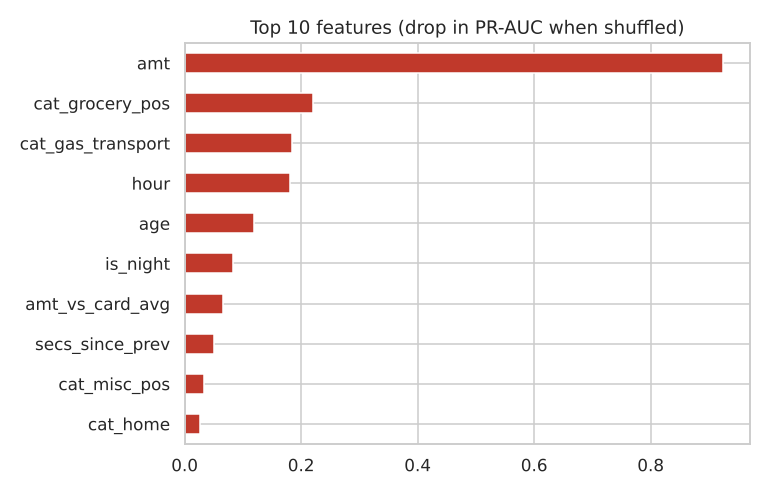

In [10]:
from sklearn.inspection import permutation_importance
samp = np.random.RandomState(RNG).choice(len(Xte), 60000, replace=False)
pi = permutation_importance(final, Xte.iloc[samp], yte.iloc[samp], scoring="average_precision", n_repeats=3, random_state=RNG, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
print(imp.head(10).round(4))
imp.head(10)[::-1].plot.barh(color="#c0392b", figsize=(7, 4.5)); plt.title("Top 10 features (drop in PR-AUC when shuffled)")
plt.tight_layout(); plt.savefig("/home/claude/fig_importance.png", dpi=110); plt.close()

In [11]:
import joblib
joblib.dump({"model": final, "features": FEATURES, "threshold": float(THRESH)}, "/home/claude/fraud_model.joblib")
print("saved fraud_model.joblib")

saved fraud_model.joblib
